# 05 · Experiments E4/E5 — density scaling and interaction density

**Questions.** RQ2 and RQ3: do the update rates that suffice at low traffic
still suffice as density rises, and is the freshness requirement better
predicted by raw density or by *interaction* density?

**Where the traffic comes from.** BUBBLES is the anchor — 14 real aircraft, and
notebook 01 measured its realised density at only **0.4–3.1 UAS/km²**. That is a
real U-space campaign but it is *not* dense. Everything above it is generated
by the traffic simulator, with speeds drawn from the BUBBLES empirical
distribution so the extrapolation inherits real speed structure.

> Figures in this notebook must keep the real anchor point visually distinct
> from the synthetic extrapolation. The paper may not describe the high-density
> points as observed.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.data.bubbles import BubblesDataset
from telemetry_freshness.evaluation.density import (
    airborne_only, density_timeline, local_density, interaction_rate, LOCAL_RADII_M)
from telemetry_freshness.simulation.traffic_generator import (
    SpeedProfile, TrafficConfig, generate_traffic)
from telemetry_freshness.experiments.runner import ScenarioConfig
from telemetry_freshness.experiments.fast_runner import run_scenario_fast
from telemetry_freshness.telemetry.network_model import TelemetryConfig
from telemetry_freshness.conflict.detector import ConflictCriteria

CRITERIA = ConflictCriteria(horizontal_separation_m=30.0, vertical_separation_m=15.0, horizon_s=30.0)

bub = BubblesDataset(); DAY = "2022_04_11"
real = airborne_only(bub.load_scenario(DAY))
profile = SpeedProfile.from_trajectories(real, source=f"BUBBLES {DAY} (14 real UAS)")
print("speed profile from real flights:", {k: round(v,2) if isinstance(v,float) else v
                                           for k, v in profile.describe().items()})

speed profile from real flights: {'source': 'BUBBLES 2022_04_11 (14 real UAS)', 'p05': 2.27, 'p50': 9.7, 'p95': 14.11}


## The real anchor: density actually achieved in BUBBLES

In [3]:
real_dens = density_timeline(real, step_s=60)
real_dens = real_dens[real_dens.n_aircraft >= 2]
display(real_dens[["n_aircraft","area_km2","density_per_km2"] +
                  [f"local_mean_{int(r)}m" for r in LOCAL_RADII_M]]
        .describe().loc[["min","50%","max"]].round(2))

,n_aircraft,area_km2,density_per_km2,local_mean_100m,local_mean_250m,local_mean_500m,local_mean_1000m
min,2.0,0.64,0.42,0.0,0.0,0.00,0.00
50%,8.0,6.24,1.14,0.0,0.0,0.25,1.27
max,14.0,11.27,3.14,0.2,0.4,0.75,3.09


## Synthetic density sweep

Aircraft count is varied over a fixed 1 km² area, holding geometry mix, speed
distribution, duration and conflict criteria constant so density is the only
factor that moves (research plan §22).

In [4]:
DENSITIES = [10, 25, 50, 75, 100]
LATENCY_MS = [0, 250, 500, 1000, 2000]
RATE_HZ = 1.0
# Conflict events scale with density, so low-density scenarios need more
# repetitions to populate the AoI bins. Budget is roughly constant per density.
SEEDS_FOR = {10: 48, 25: 24, 50: 12, 75: 8, 100: 6}
DURATION_S = 180

# record="relevant" keeps only pairs either layer called a conflict and counts
# the rest; recall, precision and TTC error are unchanged by this (verified in
# tests/test_fast_runner.py) and 100-aircraft runs become tractable.
runs, dens_rows, tn_counts = [], [], []
for n in DENSITIES:
    for seed in range(SEEDS_FOR[n]):
        tcfg = TrafficConfig(n_aircraft=n, area_km2=1.0, duration_s=DURATION_S,
                             sample_rate_hz=5.0, speed_profile=profile, seed=500+seed)
        traj = generate_traffic(tcfg)

        # Interaction density is a property of the traffic, measured once.
        ld = local_density(traj, DURATION_S/2)
        dens_rows.append({
            "density_per_km2": n, "seed": seed,
            **{f"local_mean_{int(r)}m": float(ld[f"n_within_{int(r)}m"].mean())
               for r in LOCAL_RADII_M}})

        for lat_ms in LATENCY_MS:
            cfg = ScenarioConfig(
                scenario_id=f"D{n}", criteria=CRITERIA, decision_rate_hz=2.0, seed=7000+seed,
                telemetry=TelemetryConfig(update_rate_hz=RATE_HZ, latency_ms=lat_ms,
                                          jitter_ms=0.1*lat_ms))
            r = run_scenario_fast(traj, cfg, record="relevant")
            tn_counts.append({"density_per_km2": n, "seed": seed, "latency_ms": lat_ms,
                              "n_pair_observations": r.attrs.get("n_pair_observations", 0),
                              "n_true_negative": r.attrs.get("n_true_negative", 0)})
            if r.empty: continue
            r["density_per_km2"] = n
            r["seed_index"] = seed
            runs.append(r)

E4 = pd.concat(runs, ignore_index=True)
E4.to_parquet("results/raw/E4_density_sweep.parquet", index=False)
DENS = pd.DataFrame(dens_rows)
TN = pd.DataFrame(tn_counts)
TN.to_csv("results/processed/E4_pair_counts.csv", index=False)
print(f"{len(E4):,} conflict-relevant rows retained")
print(f"{TN.n_pair_observations.sum():,} pair-observations evaluated "
      f"({TN.n_true_negative.sum():,} true negatives counted, not stored)")
display(DENS.groupby("density_per_km2").mean().round(2))

272,673 conflict-relevant rows retained
89,325,845 pair-observations evaluated (89,053,172 true negatives counted, not stored)


,seed,local_mean_100m,local_mean_250m,local_mean_500m,local_mean_1000m
density_per_km2,,,,,
10,23.5,0.10,0.33,1.46,4.42
25,11.5,0.19,1.04,4.14,12.03
50,5.5,0.35,2.17,8.19,24.24
75,3.5,0.58,3.56,12.81,37.89
100,2.5,0.63,3.99,14.87,46.55


## Figure F2 — conflict recall against information age, per density

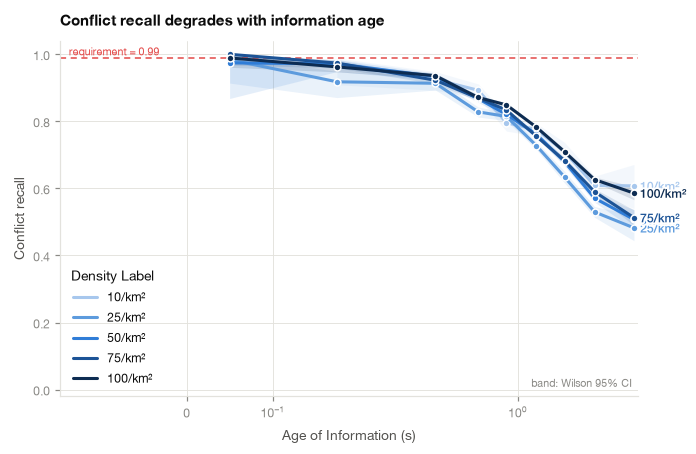

density_label,10/km²,100/km²,25/km²,50/km²,75/km²
aoi_bin,,,,,
"[0.0, 0.1)",NaN,0.9891,0.9839,0.9744,1.0000
"[0.1, 0.25)",0.9677,0.9625,0.9179,0.9716,0.9739
"[0.25, 0.5)",0.9251,0.9361,0.9135,0.9339,0.9226
"[0.5, 0.75)",0.8926,0.8711,0.8282,0.8675,0.8691
"[0.75, 1.0)",0.7958,0.8490,0.8146,0.8206,0.8337
"[1.0, 1.5)",0.7759,0.7827,0.7276,0.7615,0.7555
"[1.5, 2.0)",0.7092,0.7090,0.6337,0.6791,0.6827
"[2.0, 3.0)",0.6087,0.6264,0.5298,0.5709,0.5901
"[3.0, 5.0)",0.6077,0.5859,0.4822,0.5074,0.5127


In [5]:
from telemetry_freshness.evaluation.metrics import recall_by_aoi

curves = []
for n, g in E4.groupby("density_per_km2"):
    c = recall_by_aoi(g)
    c["density_per_km2"] = n
    c["density_label"] = f"{n}/km²"
    curves.append(c)
REC = pd.concat(curves, ignore_index=True)
REC = REC[REC.n_positive >= 30]
REC.to_csv("results/processed/E4_recall_by_aoi_density.csv", index=False)

from telemetry_freshness.evaluation.statistics import wilson_interval
lo_hi = [wilson_interval(int(r.tp), int(r.n_positive)) for _, r in REC.iterrows()]
REC["recall_lo"] = [x[0] for x in lo_hi]; REC["recall_hi"] = [x[1] for x in lo_hi]

fig, ax = F.fig_recall_vs_aoi(REC, level_col="density_label", requirement=0.99)
S.save(fig, "F2_recall_vs_aoi_by_density"); S.plt.show()
display(REC.pivot_table(index="aoi_bin", columns="density_label", values="recall").round(4))

## E5 — which predictor actually governs the requirement?

In [6]:
inter = []
for (n, seed), g in E4.groupby(["density_per_km2","seed_index"]):
    ir = interaction_rate(g, window_s=60)
    inter.append({"density_per_km2": n, "seed_index": seed,
                  "conflict_pairs_per_min": ir.conflict_pairs_per_min.mean(),
                  "converging_pairs_per_min": ir.converging_pairs_per_min.mean()})
INTER = pd.DataFrame(inter)
PRED = (INTER.merge(DENS, left_on=["density_per_km2","seed_index"],
                    right_on=["density_per_km2","seed"], how="left"))
display(PRED.groupby("density_per_km2").mean(numeric_only=True).round(2))
PRED.to_csv("results/processed/E5_predictors.csv", index=False)

,seed_index,conflict_pairs_per_min,converging_pairs_per_min,seed,local_mean_100m,local_mean_250m,local_mean_500m,local_mean_1000m
density_per_km2,,,,,,,,
10,23.54,1.68,1.70,23.54,0.11,0.34,1.47,4.57
25,11.50,6.99,7.18,11.50,0.19,1.04,4.14,12.03
50,5.50,24.00,24.97,5.50,0.35,2.17,8.19,24.24
75,3.50,59.50,61.46,3.50,0.58,3.56,12.81,37.89
100,2.50,93.06,96.56,2.50,0.63,3.99,14.87,46.55
